# CodeAlpha — Unemployment Analysis with Python

Task 2: a reproducible descriptive analysis of two distinct user-supplied datasets. Run all cells from this project directory. All aggregate rates are unweighted state or matched state-area means, not official national estimates. Covid comparisons describe association; the short history does not establish recurring seasonality.


## Run the shared pipeline

The notebook calls the same validated implementation as the CLI. Original input CSVs stay unchanged. Pinned runtime dependencies are in `requirements.txt`.


In [1]:
from analysis import main, ROOT
from IPython.display import Markdown, Image, display

metrics = main([])


Analysis complete: 25 complete state comparisons; report: /workspace/codealpha-projects/CodeAlpha_UnemploymentAnalysis/outputs/summary.md
Jan–Mar mean 9.20%; Apr–May 23.20%; Aug–Oct 8.90% (unweighted state means).


## Design report

Objectives, data coverage, method, results, policy insights, limitations, and reproducibility are generated directly from the analysis.


In [2]:
report = (ROOT / "outputs" / "summary.md").read_text()
display(Markdown(report.split("## Figures")[0]))


# Unemployment analysis — design report

## Objective

Clean the supplied unemployment datasets, explore time and regional patterns, describe Covid-period changes, and identify cautious policy implications.

## Data and scope

- `Unemployment in India.csv`: 768 raw rows; 28 fully blank rows removed; 740 valid observations covering 28 states/territories and 55 observed state-area pairs, May 2019–June 2020.
- `Unemployment_Rate_upto_11_2020.csv`: 267 observations across 27 states/territories, January–October 2020. The filename does **not** establish November coverage.
- Missing cells within each observed entity's full date span: 30 historical state-area-months and 3 2020 state-months. Chandigarh has only Urban records in the historical file; no Rural observations are invented.
- Files are analyzed separately: the historical data are Rural/Urban state-area observations; the 2020 file supplies state observations with macro-region labels. Combining them would double count overlapping months and mix granularities.
- Actual inputs are the two user-uploaded CSV files. The task PDF links to [Unemployment in India on Kaggle](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india). That task-document attribution does not independently verify the uploaded files' publisher, extraction date, survey methodology, or redistribution license; none is invented.

## Method and validation

Headers and string values are stripped; fully blank rows are removed; dates and numbers are parsed strictly. The second `Region` column, read as `Region.1`, becomes `macro_region`, while `Region` becomes `state`. Monthly frequency labels are standardized. No rates are imputed, and duplicate observation keys raise an error rather than being averaged.

All reported aggregates are **unweighted means across states/territories or matched state-area observations**, not official national population-weighted unemployment rates. Rate changes use percentage points (pp), not percentage growth. Unemployment uses the labour force as its denominator; falling participation can accompany a falling unemployment rate.

State comparisons average Jan–Mar 2020 as the pre-Covid reference, Apr–May as the initial disruption window, and Aug–Oct as later recovery. The same 25 complete states/territories appear in every window and monthly balanced trend. Incomplete states excluded: Jammu & Kashmir, Sikkim. Means are calculated within each state first and then across states; equal state weights are maintained.

For the historical plot, both areas and all 14 months are required, leaving 20 common states per area. A separate Jan–June panel keeps 20 states with both areas observed in all six months, allowing matched rural–urban period comparisons. The different panel sizes are intentional and documented.

Both files pass required-field, finite-numeric, [0,100] percentage, nonnegative integral employment-count, monthly-date, unique-key, and panel-completeness checks. Source coordinate labels appear reversed: the column named `latitude` exceeds 90 degrees. They remain under explicit `source_*_label` names and are not used for maps.

## Results

For the same 25 states, mean unemployment rises from **9.20%** in Jan–Mar to **23.20%** in Apr–May (**+14.00 pp**), then falls to **8.90%** in Aug–Oct (**-0.30 pp** relative to the reference). The monthly peak is **2020-05 (23.37%)**. 9 of 25 states remain above their own pre-Covid period average in Aug–Oct.

Unweighted labour participation for these same states changes from **44.13%** to **37.33%** and later **42.07%**. This joint movement cautions against treating a lower unemployment rate alone as complete labour-market recovery.

Largest descriptive first-wave increases:

| state | pre_covid_rate_pct | first_wave_rate_pct | first_wave_change_pp |
| --- | --- | --- | --- |
| Puducherry | 1.18 | 67.02 | 65.84 |
| Jharkhand | 10.23 | 53.16 | 42.93 |
| Tamil Nadu | 3.35 | 41.49 | 38.14 |
| Bihar | 12.11 | 46.30 | 34.19 |
| Karnataka | 3.31 | 24.91 | 21.60 |

Macro-region results on the same complete panel:

| macro_region | states | pre_covid_rate_pct | first_wave_rate_pct | later_recovery_rate_pct |
| --- | --- | --- | --- | --- |
| East | 4 | 8.66 | 33.61 | 8.74 |
| North | 7 | 14.53 | 20.10 | 14.35 |
| Northeast | 3 | 12.41 | 16.55 | 8.80 |
| South | 6 | 4.56 | 30.05 | 4.95 |
| West | 5 | 5.83 | 15.00 | 6.22 |

Matched rural/urban results (a distinct dataset and January–June comparison):

| area | states | pre_covid_rate_pct | first_wave_rate_pct | june_rate_pct | first_wave_change_pp |
| --- | --- | --- | --- | --- | --- |
| Rural | 20 | 9.48 | 23.31 | 12.94 | 13.83 |
| Urban | 20 | 12.15 | 27.92 | 13.83 | 15.77 |

The mean Urban-minus-Rural unemployment gap is **2.67 pp** before Covid, **4.61 pp** in Apr–May, and **0.89 pp** in June. These are same-state, equal-weight comparisons; they do not represent every rural or urban resident.

## Within-year patterns and limits on seasonality

- In the balanced historical rural panel's May–December 2019 observations, the highest monthly mean is 2019-10 (9.90%) and the lowest is 2019-05 (7.95%).
- In the balanced historical urban panel's May–December 2019 observations, the highest monthly mean is 2019-09 (12.06%) and the lowest is 2019-06 (10.63%).

These are observed within-year fluctuations, not evidence of a repeatable seasonal cycle. The historical series spans only 14 months, has missing entities, and includes an exceptional disruption. Several comparable years and sector, agricultural-calendar, and survey-design information would be needed to distinguish seasonality from trend and sampling variation.

## Policy implications

1. The broad Apr–May rate increase, alongside reduced participation, supports prioritizing rapid income support and access to employment services during abrupt disruptions. The analysis establishes timing and association; it cannot estimate the effect of a particular restriction or program.
2. State and macro-region variation argues for local monitoring and allocation based on both the size of the affected labour force and the severity/persistence of change. A high unweighted rate or a small region's mean should not by itself determine a national funding allocation.
3. Matched rural–urban differences motivate checking access to suitable work and income protection in both areas, including mobile and migrant workers. The data do not identify occupations or migration, so sector-specific explanations require additional evidence.
4. Track participation and employment levels alongside unemployment. A return of the unemployment percentage toward baseline can coexist with workers leaving the labour force; June observations alone do not establish durable rural/urban recovery.
5. Extend the series and obtain documented survey weights, sample sizes and uncertainty before drawing national estimates, causal claims, recurring-seasonality conclusions, or evaluating policy effectiveness.

## Limitations

No control group, policy exposure measure, sample sizes, survey weights, standard errors, or identification strategy is available. Jan–Mar is a descriptive reference rather than a proven untreated counterfactual, and March may already contain pandemic-related disruption. Missing states are excluded from paired panels, so panel results do not cover every state. No confidence intervals are fabricated. The two source datasets can differ in methodology and are never used interchangeably.

## Reproducibility

Run `python analysis.py` from any working directory. Source paths and output defaults are resolved relative to this script. Optional `--data-dir` and `--output-dir` arguments allow reruns without modifying the originals. `metrics.json` records source SHA-256 hashes and validation outcomes; CSVs retain full analysis values to six decimals. No network access is needed for analysis.



## Visual findings

The balanced state panel avoids changing sample membership. Rural/urban comparisons use their separate historical dataset and matched states.


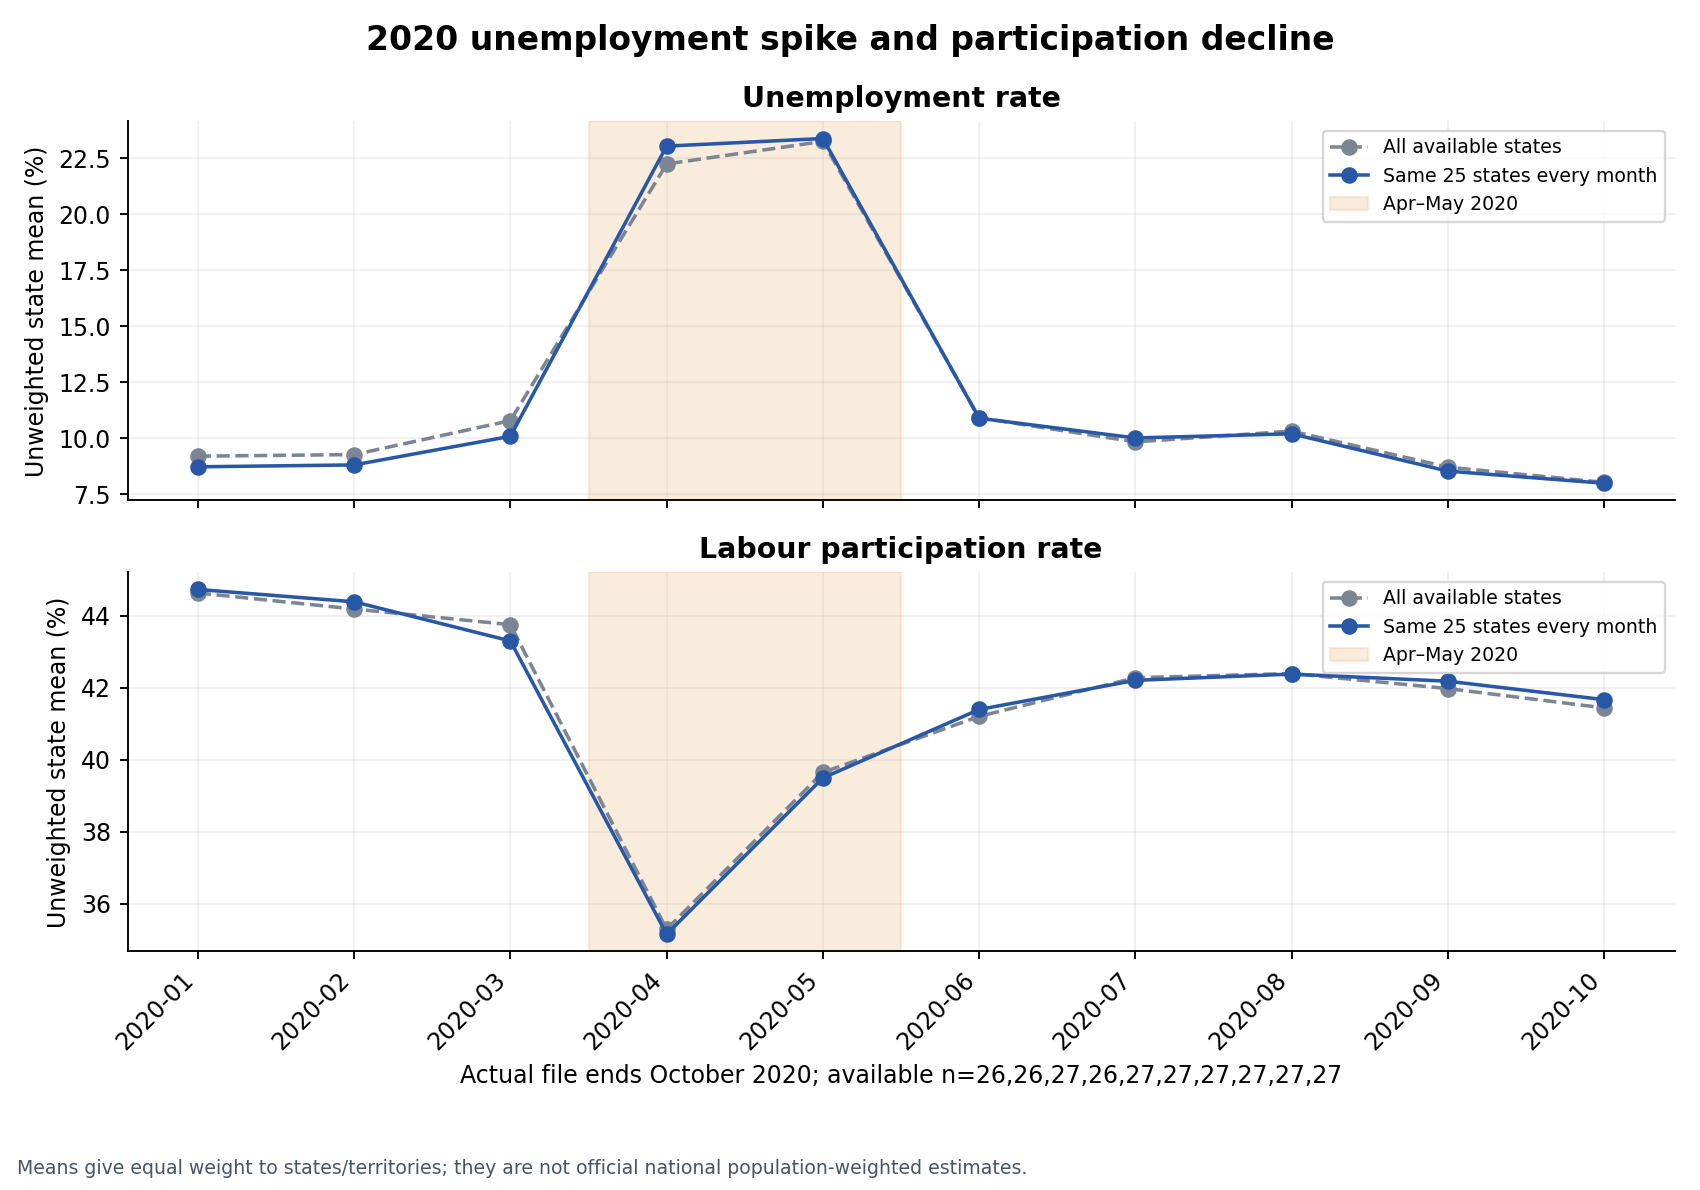

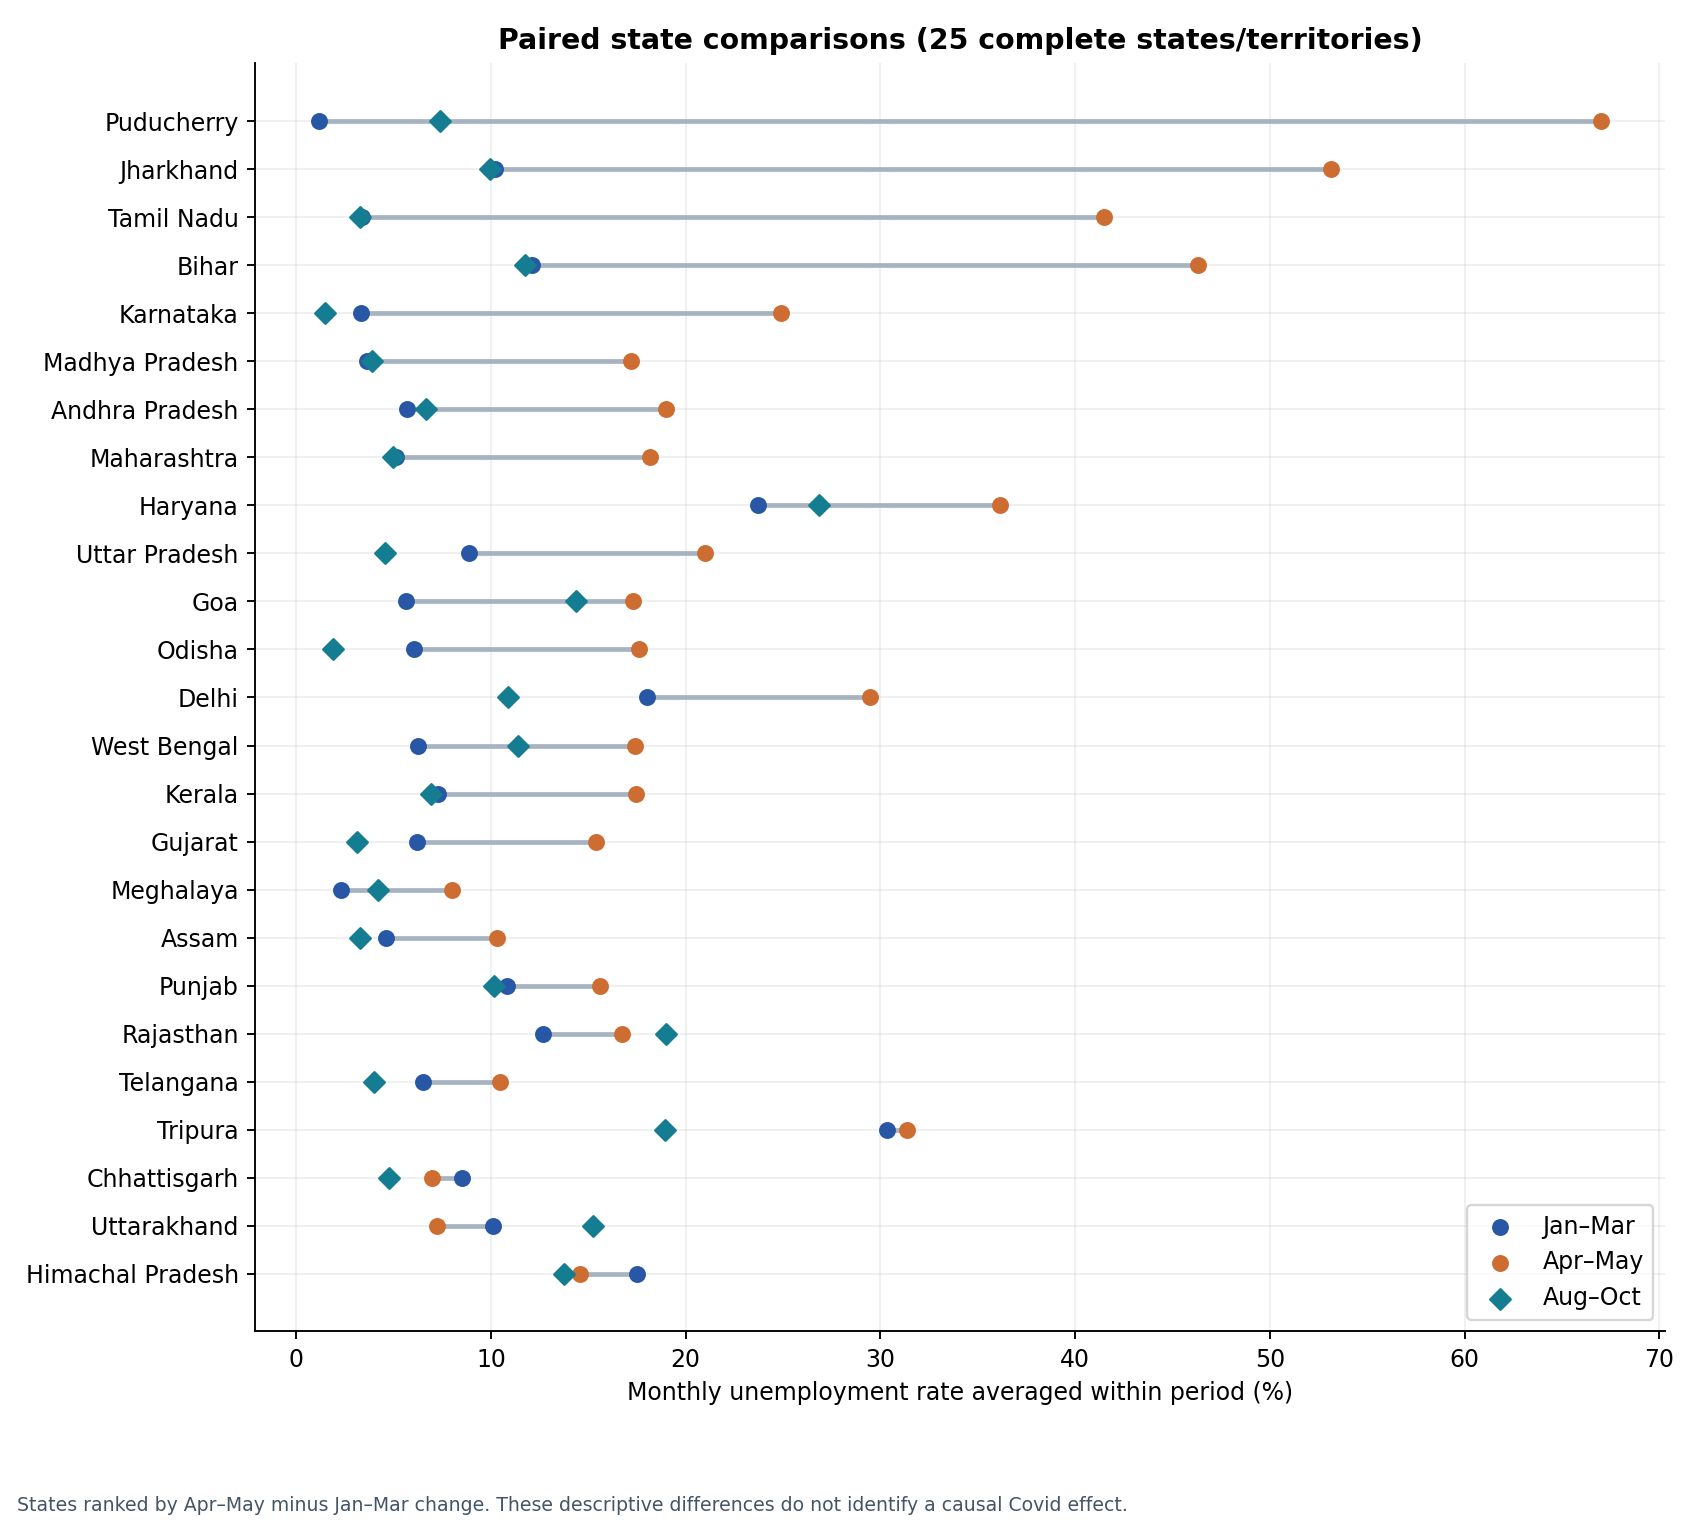

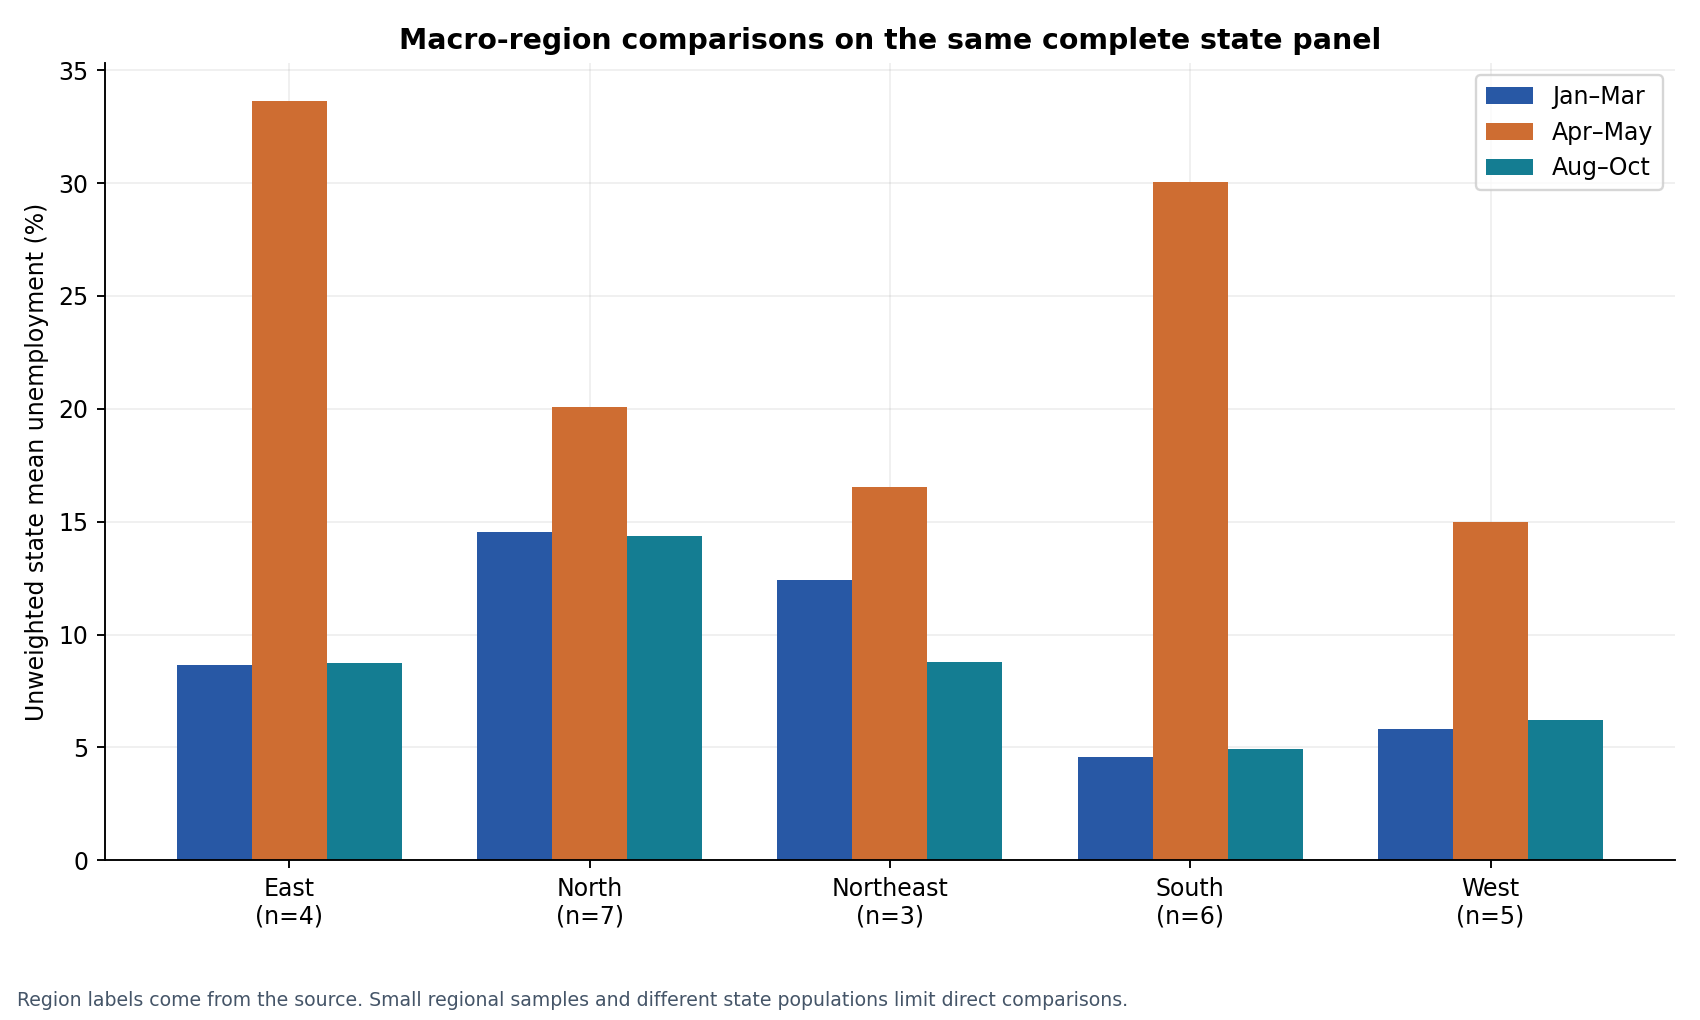

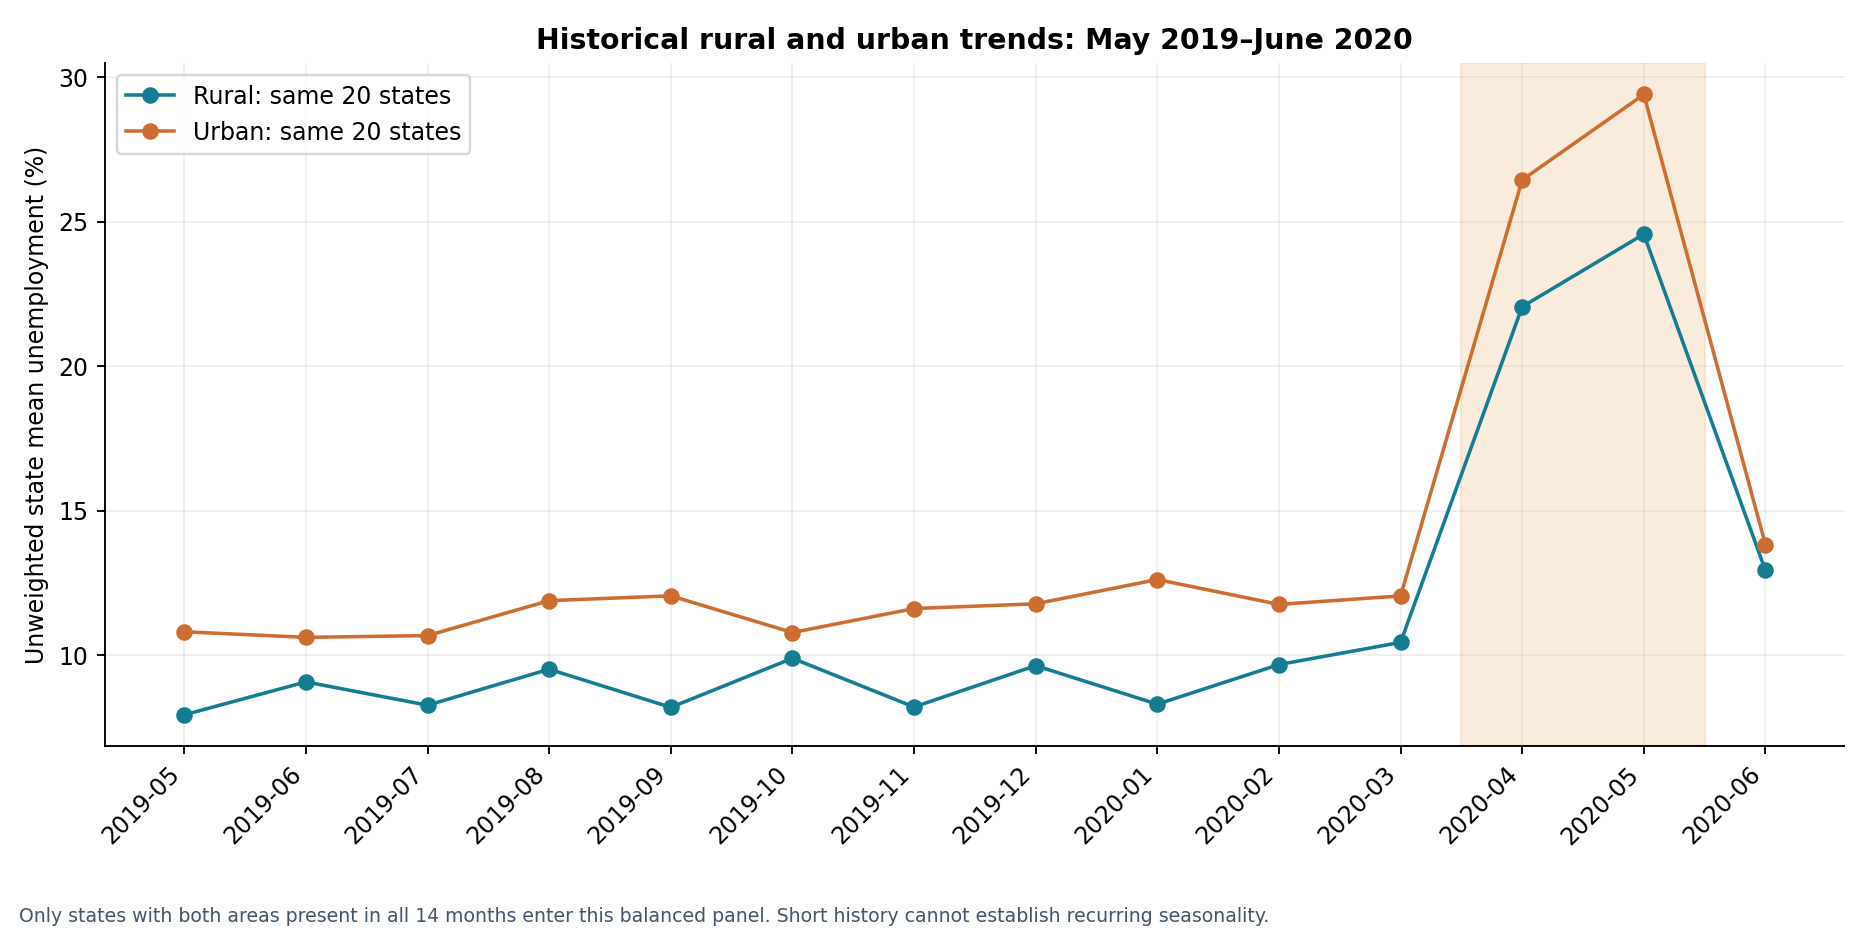

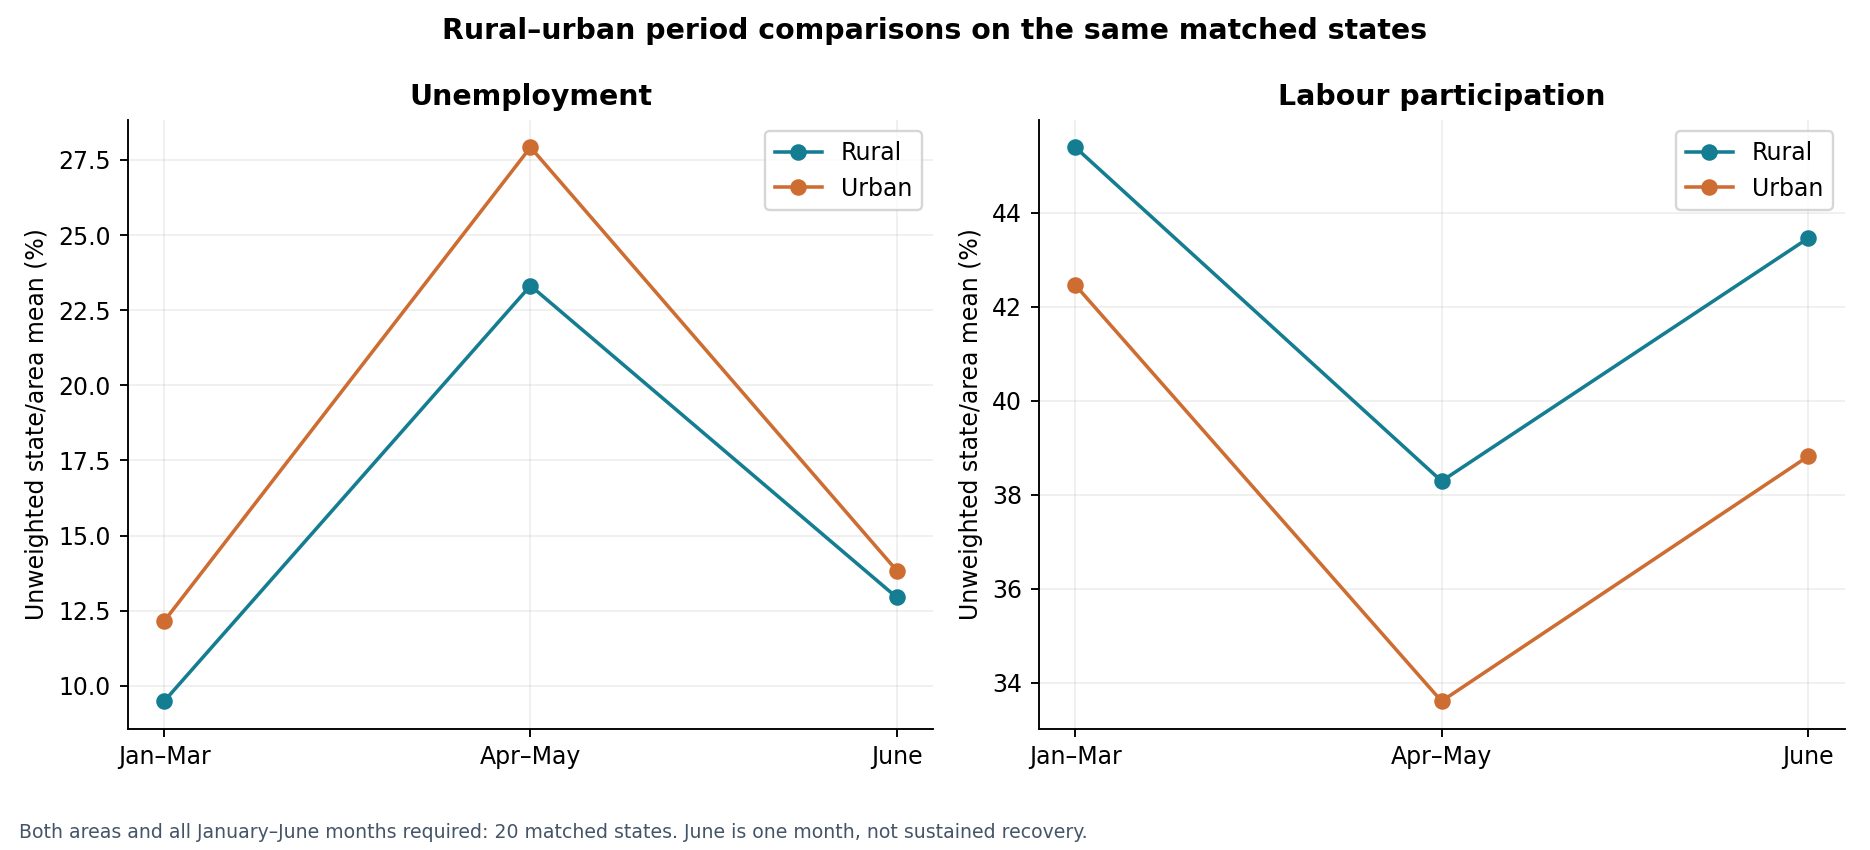

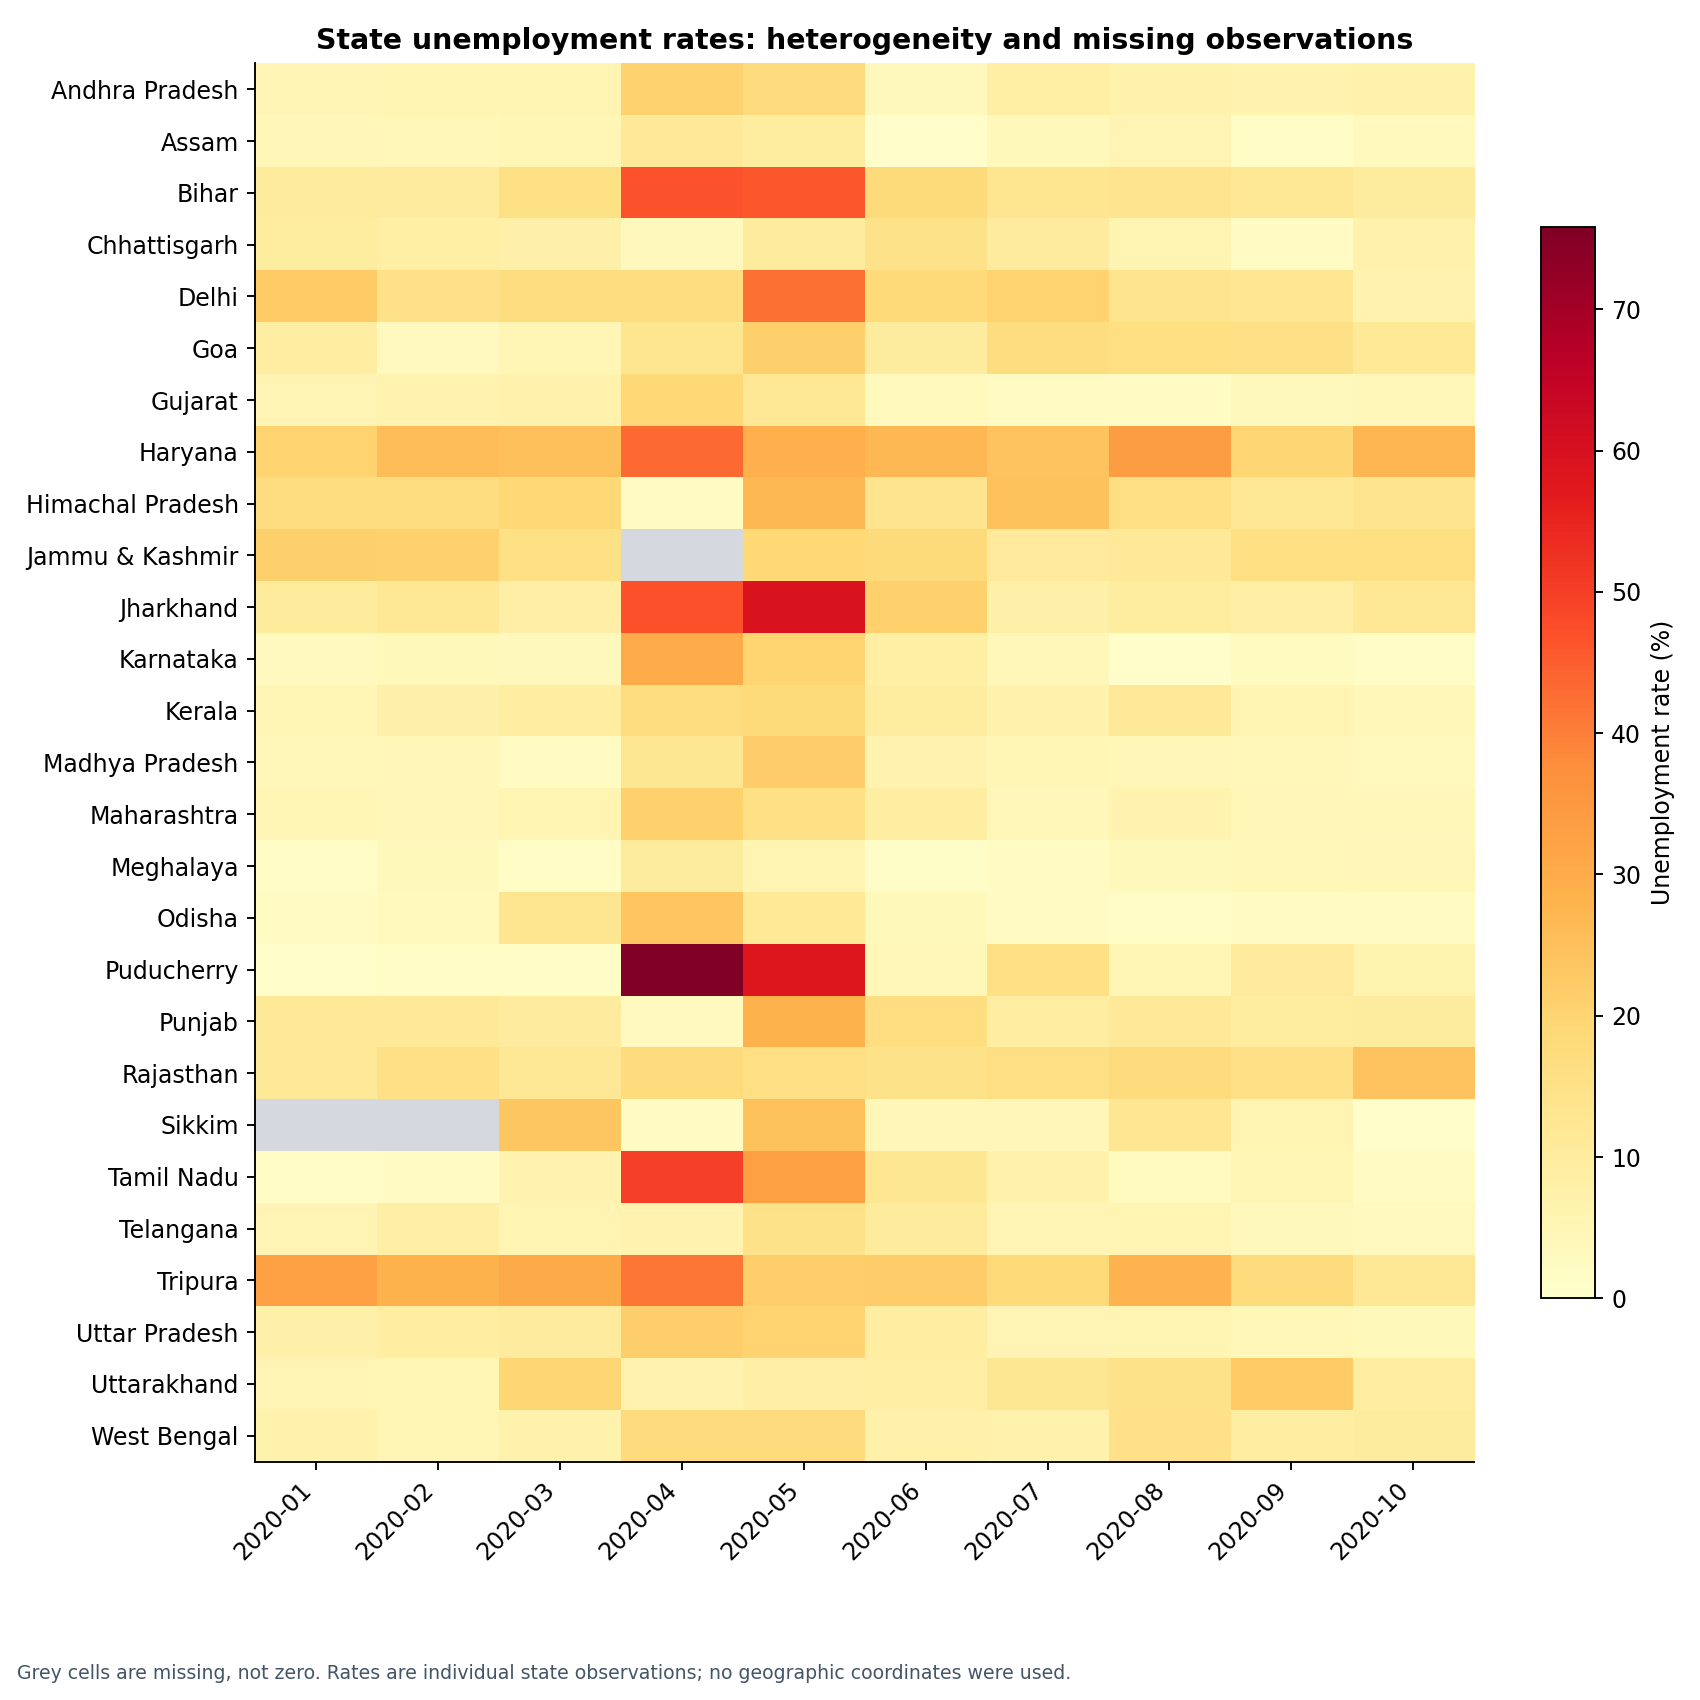

In [3]:
for filename in [
    "state_monthly_trends.png",
    "paired_state_changes.png",
    "macro_region_comparison.png",
    "rural_urban_trends.png",
    "rural_urban_period_comparison.png",
    "state_month_heatmap.png",
]:
    display(Image(filename=str(ROOT / "outputs" / "charts" / filename)))


## Machine-readable validation

Source hashes, panel membership, exact period averages, coverage information, and validation status are saved in `outputs/metrics.json`.


In [4]:
metrics["validation"]


{'required_schema': 'passed',
 'date_parsing_and_month_ends': 'passed',
 'unique_observation_keys': 'passed',
 'numeric_ranges_and_finiteness': 'passed',
 'complete_matched_comparison_panels': 'passed',
 'datasets_not_concatenated': True}